# 04. Углублённый анализ

Ноутбук 03 отвечал на вопросы медианами. Здесь проверяем выводы строже и идём глубже:

- **A. Статистическая проверка:** доверительные интервалы и тесты значимости для каждого утверждения
- **B. Уровень профессий:** 169 подкатегорий, разброс зарплат, «от» против диапазона
- **C. Текст объявлений и бонусы:** что пишут в дорогих и дешёвых вакансиях, влияние соцпакета, питания, жилья
- **D. Работодатели и публикации:** кто нанимает, кто скрывает зарплату, объявления на кыргызском

In [1]:
import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
rng = np.random.default_rng(42)

df = pd.read_csv("../data/processed/vacancies_clean.csv", parse_dates=["published"])
df["text"] = (df["name"].fillna("") + " " + df["requirements"].fillna("") + " "
              + df["responsibilities"].fillna("")).str.lower()
sal = df[df["has_salary"]].copy()
print(len(df), len(sal))

12646 5840


# A. Статистическая проверка выводов

Медиана по выборке — это оценка. Чтобы сказать «группа A платит больше группы B», нужно показать,
что разница не случайна. Используем:

- **бутстрап** (2 000 перевыборок) → 95% доверительный интервал для отношения медиан;
- **тест Манна–Уитни** (непараметрический: не требует нормальности, подходит для скошенных зарплат);
- **размер эффекта** — вероятность того, что случайная вакансия из A платит больше случайной из B
  (0,5 = нет разницы).

In [2]:
def boot_ratio(a, b, n=2000):
    a, b = np.asarray(a), np.asarray(b)
    ra = rng.choice(a, (n, len(a))); rb = rng.choice(b, (n, len(b)))
    r = np.median(ra, axis=1) / np.median(rb, axis=1)
    return np.percentile(r, [2.5, 97.5])

def compare(name, a, b):
    a, b = a.dropna(), b.dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    lo, hi = boot_ratio(a, b)
    return {"утверждение": name, "n_A": len(a), "n_B": len(b),
            "медиана_A": a.median(), "медиана_B": b.median(),
            "разница_%": (a.median() / b.median() - 1) * 100,
            "CI_low_%": (lo - 1) * 100, "CI_high_%": (hi - 1) * 100,
            "p_value": p, "P(A>B)": u / (len(a) * len(b))}

S = sal["salary_kgs"]
lal = sal[sal["source"] == "lalafo"]
claims = pd.DataFrame([
    compare("hh vs lalafo", S[sal.source == "headhunter"], S[sal.source == "lalafo"]),
    compare("Бишкек vs регионы", S[sal.city == "Бишкек"], S[sal.city != "Бишкек"]),
    compare("1–3 года vs без опыта", S[sal.experience == "1–3 года"], S[sal.experience == "нет опыта"]),
    compare("3–6 лет vs без опыта", S[sal.experience == "3–6 лет"], S[sal.experience == "нет опыта"]),
    compare("6+ лет vs без опыта", S[sal.experience == "6+ лет"], S[sal.experience == "нет опыта"]),
    compare("высшее образование vs не указано", S[sal.education == "высшее"], S[sal.education == "не указано"]),
    compare("«для женщин» vs без требования (lalafo)", lal.loc[lal.gender_req == "женщины", "salary_kgs"],
            lal.loc[lal.gender_req == "не указано", "salary_kgs"]),
    compare("удалёнка vs нет", S[sal.remote], S[~sal.remote]),
    compare("проценты/бонусы vs нет", S[sal.commission], S[~sal.commission]),
])
claims["значимо (p<0.05)"] = np.where(claims["p_value"] < 0.05, "да", "нет")
claims.round({"медиана_A": 0, "медиана_B": 0, "разница_%": 1, "CI_low_%": 1, "CI_high_%": 1,
              "p_value": 4, "P(A>B)": 2})

,утверждение,n_A,n_B,медиана_A,медиана_B,разница_%,CI_low_%,CI_high_%,p_value,P(A>B),значимо (p<0.05)
0,hh vs lalafo,2028,3812,40000.0,35000.0,14.3,11.4,21.4,0.0000,0.59,да
1,Бишкек vs регионы,5051,789,39000.0,34000.0,14.7,7.1,28.2,0.0000,0.56,да
2,1–3 года vs без опыта,2414,2606,39140.0,32500.0,20.4,14.3,28.2,0.0000,0.56,да
3,3–6 лет vs без опыта,604,2606,50000.0,32500.0,53.8,43.9,60.3,0.0000,0.67,да
4,6+ лет vs без опыта,216,2606,45000.0,32500.0,38.5,18.3,60.3,0.0003,0.57,да
5,высшее образование vs не указано,453,5359,40000.0,39000.0,2.6,2.6,6.7,0.0018,0.54,да
6,«для женщин» vs без требования (lalafo),387,3259,30000.0,36400.0,-17.6,-26.7,-14.3,0.0000,0.39,да
7,удалёнка vs нет,82,5758,37183.0,39000.0,-4.7,-19.7,13.2,0.5582,0.48,нет
8,проценты/бонусы vs нет,364,5476,50000.0,38500.0,29.9,15.4,33.3,0.0000,0.61,да


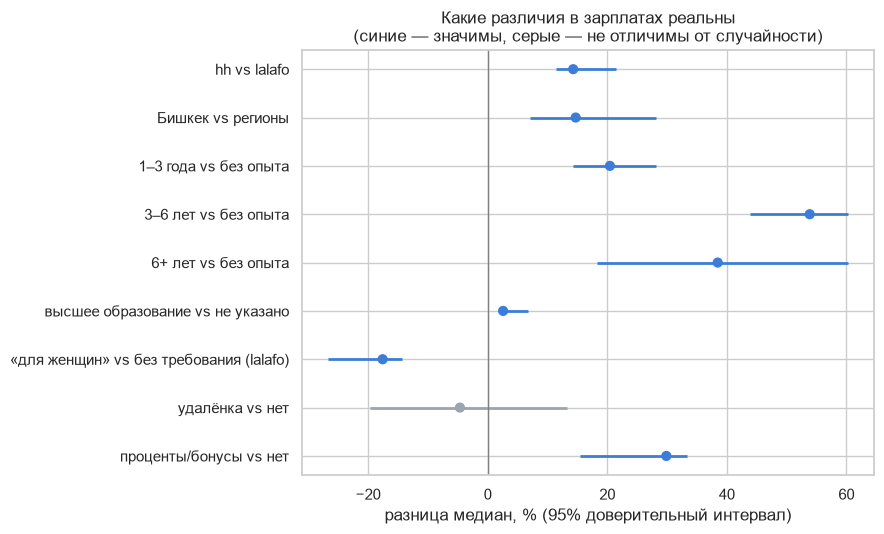

In [3]:
c = claims.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
col = np.where(c["значимо (p<0.05)"] == "да", "#3b7dd8", "#9aa5b1")
for i, (lo, hi, cl) in enumerate(zip(c["CI_low_%"], c["CI_high_%"], col)):
    ax.hlines(i, lo, hi, color=cl, lw=2)
ax.scatter(c["разница_%"], range(len(c)), color=col, zorder=3, s=40)
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(c))); ax.set_yticklabels(c["утверждение"])
ax.set_xlabel("разница медиан, % (95% доверительный интервал)")
ax.set_title("Какие различия в зарплатах реальны\n(синие — значимы, серые — не отличимы от случайности)")
plt.tight_layout(); plt.savefig(FIG + "04_a_forest.png", dpi=150); plt.show()

**Как читать:** если интервал не пересекает ноль, разница устойчива. Широкий интервал = мало данных.

**Вывод A:**
- Подтвердились: hh > lalafo (+14%), Бишкек > регионы (+15%), опыт 3–6 лет (+54%), «женские» вакансии ниже (−18%),
  вакансии с процентами/бонусами выше (+30%).
- **Значимо ≠ важно:** высшее образование статистически значимо, но эффект всего ~+3% — практически ничтожен.
- **Не подтвердилось:** удалённая работа не отличается по оплате (интервал от −20% до +13%, всего 82 вакансии).
- 6+ лет: интервал широкий (18–60%) — вакансий мало, оценка ненадёжна.
- Скрытие зарплаты связано с опытом и источником значимо, но **слабо** (Cramér's V ≈ 0,1): опыт объясняет
  скрытность лишь частично — главное, как покажет раздел D, кто работодатель.

In [4]:
# Несколько групп сразу: тест Краскела–Уоллиса
for col in ["experience", "category", "city", "schedule"]:
    groups = [g["salary_kgs"].values for _, g in sal.groupby(col) if len(g) >= 30]
    h, p = stats.kruskal(*groups)
    print(f"{col:12s} групп={len(groups):2d}  H={h:8.1f}  p={p:.1e}")

experience   групп= 4  H=   214.4  p=3.3e-46
category     групп=19  H=   940.2  p=4.2e-188
city         групп= 3  H=    27.1  p=1.3e-06
schedule     групп= 4  H=    19.6  p=2.1e-04


In [5]:
# Скрытие зарплаты зависит от опыта и источника? Тест хи-квадрат
for col in ["experience", "source", "city"]:
    tab = pd.crosstab(df[col], df["salary_hidden"])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    print(f"{col:12s} chi2={chi2:7.1f}  p={p:.1e}  Cramér's V={v:.2f}")

experience   chi2=   98.9  p=2.7e-21  Cramér's V=0.09
source       chi2=  213.6  p=2.2e-48  Cramér's V=0.13
city         chi2=   46.0  p=1.0e-10  Cramér's V=0.06


Cramér's V показывает силу связи (0 — нет, 0,1 — слабая, 0,3 — средняя).

# B. Уровень профессий

Категорий 27, а подкатегорий — 169. Внутри одной категории зарплаты сильно различаются,
поэтому смотрим на конкретные профессии (подкатегории с ≥ 25 зарплатами).

Профессий для анализа: 43


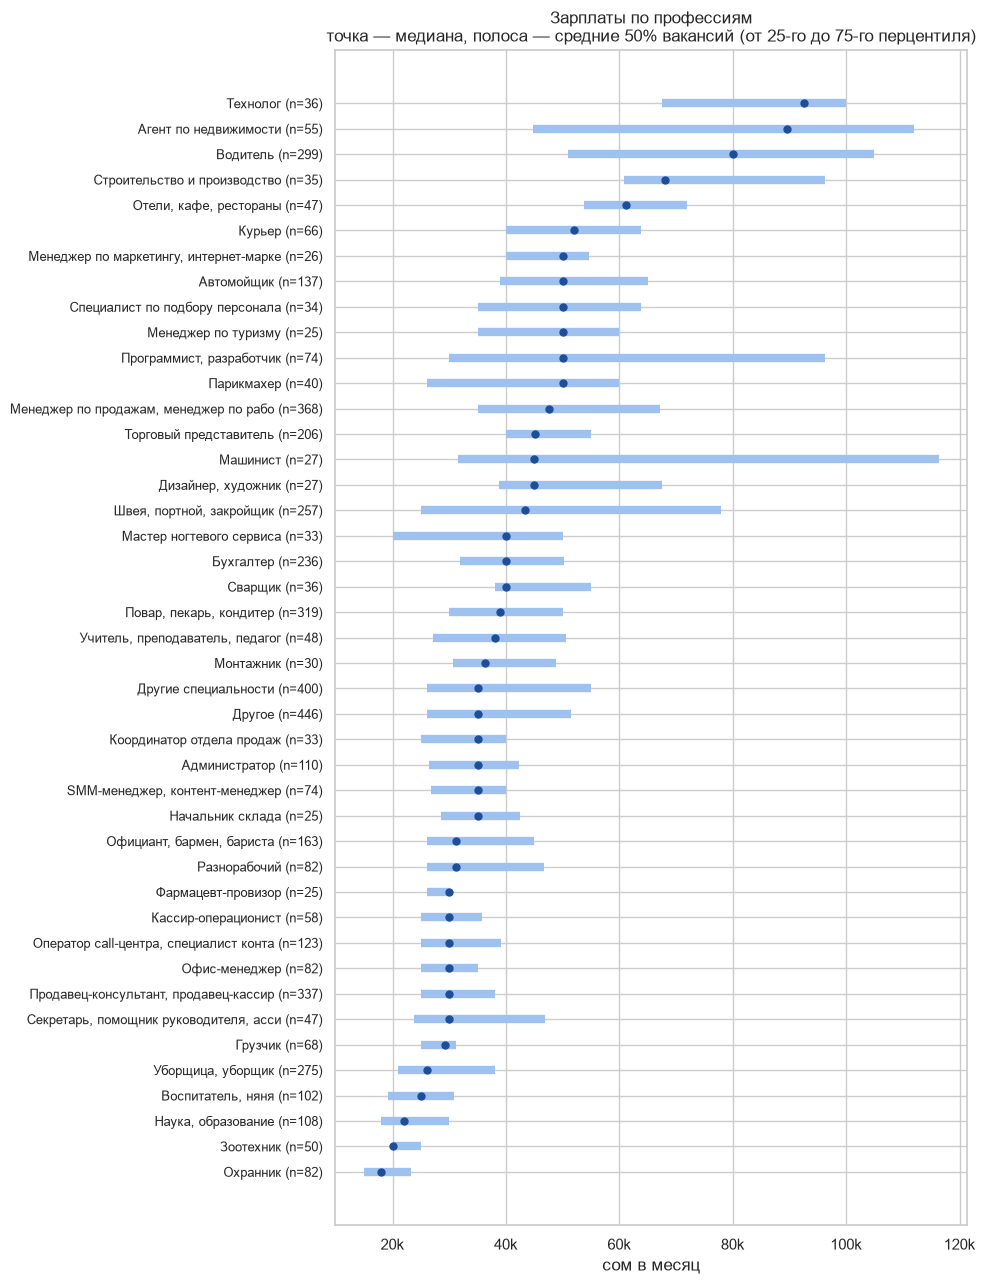

In [6]:
roles = sal.groupby("sub_category")["salary_kgs"].agg(
    n="size", q25=lambda s: s.quantile(.25), median="median", q75=lambda s: s.quantile(.75))
roles = roles[roles["n"] >= 25].sort_values("median")
roles["разброс"] = ((roles["q75"] - roles["q25"]) / roles["median"]).round(2)
print("Профессий для анализа:", len(roles))

fig, ax = plt.subplots(figsize=(10, 13))
y = range(len(roles))
ax.hlines(y, roles["q25"], roles["q75"], color="#9ec1f0", lw=6)
ax.scatter(roles["median"], y, color="#1f4e99", zorder=3, s=25)
ax.set_yticks(list(y)); ax.set_yticklabels([f"{r[:38]} (n={n})" for r, n in zip(roles.index, roles["n"])], fontsize=9)
ax.xaxis.set_major_formatter(K); ax.set_xlabel("сом в месяц")
ax.set_title("Зарплаты по профессиям\nточка — медиана, полоса — средние 50% вакансий (от 25-го до 75-го перцентиля)")
plt.tight_layout(); plt.savefig(FIG + "04_b_roles.png", dpi=150); plt.show()

In [7]:
print("Самый большой разброс внутри профессии (IQR / медиана):")
roles.sort_values("разброс", ascending=False).head(8)[["n", "q25", "median", "q75", "разброс"]]

Самый большой разброс внутри профессии (IQR / медиана):


,n,q25,median,q75,разброс
sub_category,,,,,
Машинист,27,31500.0,45000.0,116263.750,1.88
"Программист, разработчик",74,30000.0,50000.0,96326.775,1.33
"Швея, портной, закройщик",257,25000.0,43300.0,77940.000,1.22
Другие специальности,400,26000.0,35000.0,55000.000,0.83
"Секретарь, помощник руководителя, ассистент",47,23750.0,30000.0,46962.500,0.77
Мастер ногтевого сервиса,33,20000.0,40000.0,50000.000,0.75
Агент по недвижимости,55,44743.5,89487.0,111858.750,0.75
Другое,446,26000.0,35000.0,51500.000,0.73


In [8]:
print("Самый маленький разброс (зарплата почти фиксирована):")
roles.sort_values("разброс").head(6)[["n", "q25", "median", "q75", "разброс"]]

Самый маленький разброс (зарплата почти фиксирована):


,n,q25,median,q75,разброс
sub_category,,,,,
Фармацевт-провизор,25,26000.0,30000.0,30000.00,0.13
Грузчик,68,25000.0,29300.0,31200.00,0.21
Зоотехник,50,20000.0,20000.0,25000.00,0.25
"Менеджер по маркетингу, интернет-маркетолог",26,40000.0,50000.0,54673.05,0.29
"Отели, кафе, рестораны",47,53692.2,61100.0,71900.00,0.30
Торговый представитель,206,40000.0,45125.0,55000.00,0.33


**Вывод:** самые высокие медианы — технолог, агент по недвижимости, водитель (80–93 тыс.);
самые низкие — охранник, зоотехник, наука/образование, няня (18–25 тыс.).
Самый большой разброс внутри профессии — машинист, программист, швея: одна и та же профессия
стоит от 30 до 100+ тыс. в зависимости от уровня и работодателя. Почти фиксированная оплата —
у фармацевтов, грузчиков, офис-менеджеров.

### Как указывают зарплату: «от X», диапазон или «до Y»

У «от X» реальная оплата обычно выше X. Насколько широки диапазоны?

In [9]:
t = sal.groupby("salary_type")["salary_kgs"].agg(["size", "median"])
t["доля"] = (t["size"] / t["size"].sum()).round(2)
print(t, "\n")
rg = sal[sal["salary_type"] == "range"]
width = (rg["compensation_to"] / rg["compensation_from"]).replace([np.inf], np.nan).dropna()
width = width[width.between(1, 5)]
print(f"Ширина диапазона «до/от»: медиана {width.median():.2f}, 75% диапазонов уже чем ×{width.quantile(.75):.2f}")
print(pd.crosstab(sal["source"], sal["salary_type"], normalize="index").round(2))

             size   median  доля
salary_type                     
from         4513  35000.0  0.77
range        1248  45000.0  0.21
to             79  40000.0  0.01 

Ширина диапазона «до/от»: медиана 1.60, 75% диапазонов уже чем ×2.00
salary_type  from  range    to
source                        
headhunter   0.35   0.62  0.04
lalafo       1.00   0.00  0.00


**Вывод:** на lalafo зарплата всегда записана как одно число в поле «от» — значит, «от X» на lalafo
это **не нижняя граница**, а просто способ хранения. Настоящие диапазоны есть только на hh (62% вакансий),
типичный диапазон: верхняя граница в 1,6 раза выше нижней. Для модели это значит: `salary_type`
смешивает формат источника и смысл, его нужно использовать вместе с источником.

# C. Текст объявлений и бонусы

### Бонусы и условия
Ищем упоминания в тексте. Чтобы не спутать эффект бонуса со сферой (питание чаще в общепите,
где платят меньше), считаем **разницу внутри каждой категории** и берём медиану этих разниц.

In [10]:
BENEFITS = {
    "питание":           r"питани|обед за сч|кормим|бесплатн\w* обед",
    "жильё":             r"жиль|проживани|общежит",
    "официальное оформление": r"официальн\w* трудоустр|официальн\w* оформл|соцпакет|соц\.? ?пакет|трудов\w* книж",
    "обучение":          r"обучени|обучаем|стажировк",
    "премии и бонусы":   r"бонус|преми",
    "карьерный рост":    r"карьерн|рост",
    "проезд/развозка":   r"развоз|проезд",
}
rows = []
for b, pat in BENEFITS.items():
    m_all = df["text"].str.contains(pat)
    m = sal["text"].str.contains(pat)
    g = sal.assign(m=m).groupby(["category", "m"])["salary_kgs"].agg(["median", "size"]).unstack()
    ok = (g["size"][True] >= 10) & (g["size"][False] >= 10)
    within = (g["median"][True] / g["median"][False] - 1)[ok].median() * 100
    p = stats.mannwhitneyu(sal.loc[m, "salary_kgs"], sal.loc[~m, "salary_kgs"]).pvalue
    rows.append({"условие": b, "доля_вакансий_%": m_all.mean() * 100,
                 "медиана_с": sal.loc[m, "salary_kgs"].median(), "медиана_без": sal.loc[~m, "salary_kgs"].median(),
                 "разница_внутри_сферы_%": within, "сфер": int(ok.sum()), "p_value": p})
ben = pd.DataFrame(rows).sort_values("разница_внутри_сферы_%")
ben.round(1)

,условие,доля_вакансий_%,медиана_с,медиана_без,разница_внутри_сферы_%,сфер,p_value
6,проезд/развозка,0.7,41000.0,39000.0,-6.6,2,0.3
2,официальное оформление,2.3,44000.0,39000.0,-0.3,7,0.0
0,питание,3.6,40000.0,39000.0,0.0,7,0.7
5,карьерный рост,3.9,40000.0,39000.0,0.0,11,0.4
4,премии и бонусы,3.4,50000.0,39000.0,2.6,7,0.0
3,обучение,6.5,40000.0,39000.0,6.2,10,0.1
1,жильё,3.9,55000.0,38000.0,9.7,8,0.0


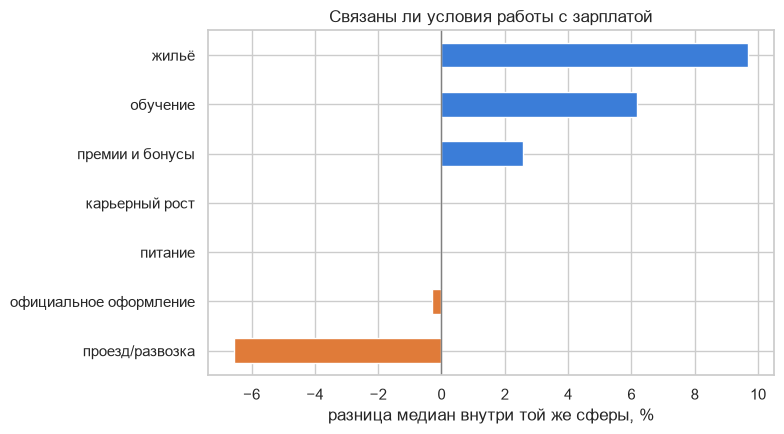

In [11]:
b = ben.dropna(subset=["разница_внутри_сферы_%"])
ax = b.plot(x="условие", y="разница_внутри_сферы_%", kind="barh", legend=False, figsize=(8, 4.5),
            color=np.where(b["разница_внутри_сферы_%"] >= 0, "#3b7dd8", "#e07b39"))
ax.axvline(0, color="grey", lw=1); ax.set_ylabel("")
ax.set_xlabel("разница медиан внутри той же сферы, %")
ax.set_title("Связаны ли условия работы с зарплатой")
plt.tight_layout(); plt.savefig(FIG + "04_c_benefits.png", dpi=150); plt.show()

### Слова дорогих и дешёвых вакансий

Сравниваем тексты верхней четверти по зарплате (75%+) и нижней (до 25%).
Метрика — логарифм отношения шансов слова с небольшим сглаживанием: показывает, какие слова
**отличают** группы, а не просто самые частые.

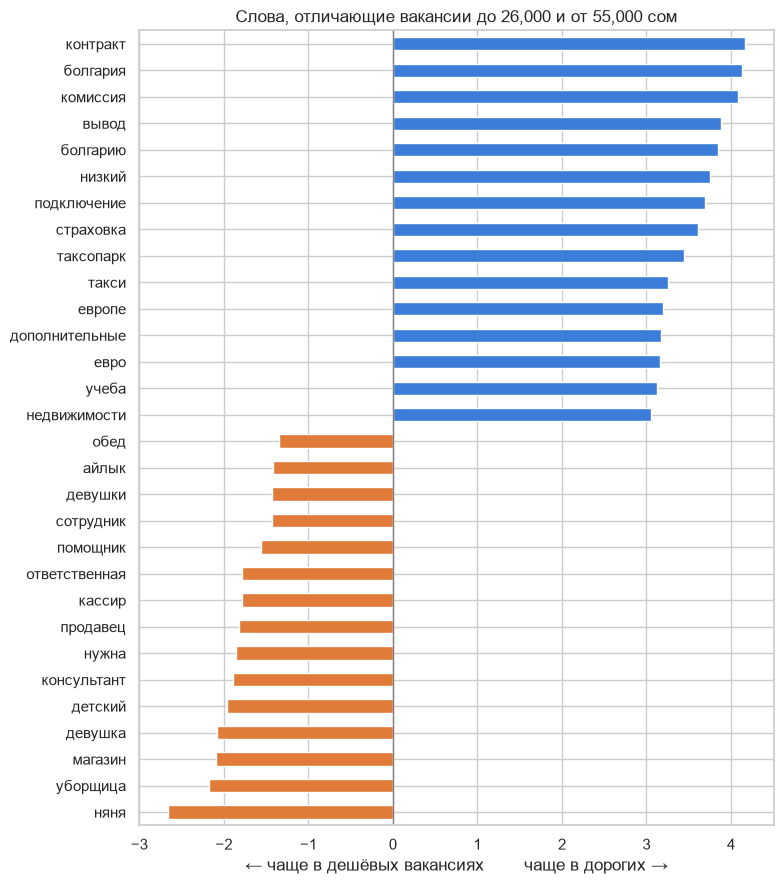

In [12]:
STOP = set('''и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот от
меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж вам ведь там
потом себя ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтоб без будто чего раз тоже себе под
будет ж тогда кто этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были куда зачем
всех никогда можно при наконец два об другой хоть после над больше тот через эти нас про всего них какая много разве три
эту моя впрочем хорошо свою этой перед иногда лучше чуть том нельзя такой им более всегда конечно всю между работы работа
требуется требования опыт опыта также наш нашу нашей компании компания вакансия'''.split())

def tokens(s):
    return [w for w in re.findall(r"[а-яёa-zөүң]{4,}", s) if w not in STOP]

q25, q75 = sal["salary_kgs"].quantile([.25, .75])
hi_c = Counter(w for s in sal.loc[sal.salary_kgs >= q75, "text"] for w in set(tokens(s)))
lo_c = Counter(w for s in sal.loc[sal.salary_kgs <= q25, "text"] for w in set(tokens(s)))
n_hi, n_lo = (sal.salary_kgs >= q75).sum(), (sal.salary_kgs <= q25).sum()
vocab = [w for w in set(hi_c) | set(lo_c) if hi_c[w] + lo_c[w] >= 40]
lor = pd.Series({w: np.log((hi_c[w] + 1) / (n_hi - hi_c[w] + 1)) - np.log((lo_c[w] + 1) / (n_lo - lo_c[w] + 1))
                 for w in vocab}).sort_values()
words = pd.concat([lor.head(15), lor.tail(15)])
ax = words.plot(kind="barh", figsize=(8, 9), color=np.where(words > 0, "#3b7dd8", "#e07b39"))
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("← чаще в дешёвых вакансиях        чаще в дорогих →")
ax.set_title(f"Слова, отличающие вакансии до {q25:,.0f} и от {q75:,.0f} сом")
plt.tight_layout(); plt.savefig(FIG + "04_c_words.png", dpi=150); plt.show()

**Вывод:** у дорогих вакансий выделяются три группы слов: **такси** (таксопарк, комиссия, подключение) —
это доход водителя, а не оклад; **работа за границей** (Болгария, Европа, евро, контракт, страховка);
**недвижимость**. У дешёвых — няня, уборщица, кассир, продавец, магазин и обращения к женщинам
(«девушка», «ответственная») — то же, что показал анализ пола.

In [13]:
# Длина описания и зарплата
sal["len_bin"] = pd.qcut(sal["text_len"], 5, labels=["очень короткое", "короткое", "среднее", "длинное", "очень длинное"])
print(sal.groupby("len_bin", observed=True)["salary_kgs"].agg(["median", "size"]))
print("\nSpearman(длина текста, зарплата):", round(sal["text_len"].corr(sal["salary_kgs"], method="spearman"), 2))

                 median  size
len_bin                      
очень короткое  32500.0  1182
короткое        35000.0  1177
среднее         40000.0  1147
длинное         39000.0  1175
очень длинное   44743.5  1159

Spearman(длина текста, зарплата): 0.14


# D. Работодатели и публикации

Название компании есть почти только у hh, поэтому анализ работодателей — по hh.

In [14]:
hh_all = df[df["source"] == "headhunter"]
emp = hh_all.groupby("company").agg(вакансий=("id", "size"), скрыто=("salary_hidden", "mean"),
                                    медиана=("salary_kgs", "median"))
print("Работодателей на hh:", len(emp), "| из них с 1 вакансией:", (emp["вакансий"] == 1).sum())
top10_share = emp["вакансий"].nlargest(10).sum() / emp["вакансий"].sum()
print(f"Топ-10 работодателей дают {top10_share:.0%} вакансий hh")
emp.sort_values("вакансий", ascending=False).head(15).round(2)

Работодателей на hh: 1586 | из них с 1 вакансией: 869
Топ-10 работодателей дают 8% вакансий hh


,вакансий,скрыто,медиана
company,,,
Банк Компаньон,56,1.00,NaN
Банк Азии,44,1.00,NaN
БАКАЙ БАНК,36,1.00,NaN
Финансовый сервис О!Деньги (ОсОО Грин Телеком Сервис),24,0.96,15000.0
Оптима Банк,24,1.00,NaN
ОсОО Неман-Фарм,23,1.00,NaN
Коммерческий банк КЫРГЫЗСТАН,22,0.91,32500.0
ОсОО П.Хазар & Ассошиэйтс,19,0.05,135000.0
FINСA Bank,19,1.00,NaN


Работодателей с ≥5 вакансиями: 117
  всегда скрывают зарплату: 37%
  всегда указывают:         22%


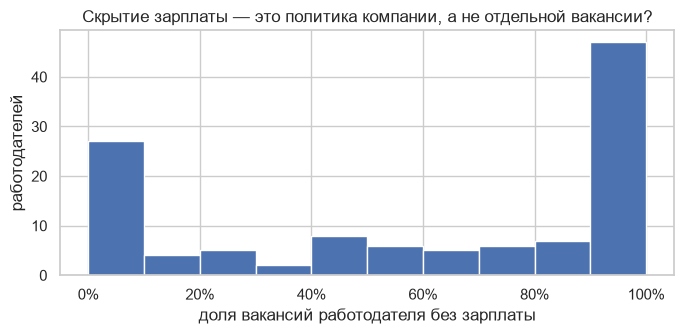

In [15]:
# Скрывают ли зарплату одни и те же работодатели? Смотрим работодателей с ≥5 вакансиями
e5 = emp[emp["вакансий"] >= 5]
print(f"Работодателей с ≥5 вакансиями: {len(e5)}")
print(f"  всегда скрывают зарплату: {(e5['скрыто'] == 1).mean():.0%}")
print(f"  всегда указывают:         {(e5['скрыто'] == 0).mean():.0%}")
ax = e5["скрыто"].plot(kind="hist", bins=10, figsize=(7, 3.5))
ax.xaxis.set_major_formatter(mt.PercentFormatter(1))
ax.set_xlabel("доля вакансий работодателя без зарплаты"); ax.set_ylabel("работодателей")
ax.set_title("Скрытие зарплаты — это политика компании, а не отдельной вакансии?")
plt.tight_layout(); plt.savefig(FIG + "04_d_employers.png", dpi=150); plt.show()

In [16]:
# Банки и финансовые компании — крупнейшие наниматели на hh
banks = hh_all["company"].fillna("").str.contains(r"банк|bank|финанс|деньги|кредит|микрофин", case=False)
print(f"Вакансий банков/финансов на hh: {banks.mean():.0%}")
print(hh_all.assign(bank=banks).groupby("bank").agg(скрыто=("salary_hidden", "mean"),
                                                   медиана=("salary_kgs", "median"), n=("id", "size")).round(2))

Вакансий банков/финансов на hh: 11%
       скрыто  медиана     n
bank                        
False    0.34  40000.0  3049
True     0.94  40000.0   388


In [17]:
# Объявления на кыргызском языке
print(df.groupby("kyrgyz_text").agg(доля=("id", lambda s: len(s) / len(df)), скрыто=("salary_hidden", "mean")).round(3))
print(sal.groupby("kyrgyz_text")["salary_kgs"].agg(["median", "size"]))

              доля  скрыто
kyrgyz_text               
False        0.982   0.515
True         0.018   0.520
              median  size
kyrgyz_text               
False        39000.0  5738
True         31600.0   102


/var/folders/5x/dkvkn8jd4699yk03gyv9ryyw0000gn/T/ipykernel_60725/3719017041.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d = df[df["published"] >= "2024-02-01"].assign(dow=lambda x: x["published"].dt.dayofweek)


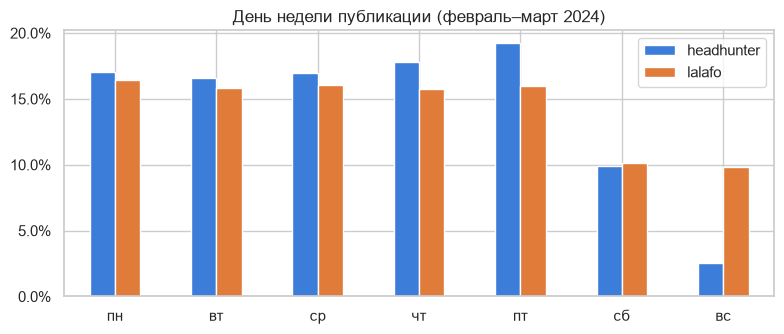

In [18]:
# Когда публикуют вакансии
dow = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
d = df[df["published"] >= "2024-02-01"].assign(dow=lambda x: x["published"].dt.dayofweek)
tab = pd.crosstab(d["dow"], d["source"], normalize="columns").set_axis(dow)
ax = tab.plot(kind="bar", figsize=(8, 3.5), color=["#3b7dd8", "#e07b39"])
ax.yaxis.set_major_formatter(mt.PercentFormatter(1)); ax.set_xlabel(""); ax.legend(title="")
ax.set_title("День недели публикации (февраль–март 2024)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "04_d_weekday.png", dpi=150); plt.show()

## Итоги углублённого анализа

| Блок | Главный вывод |
|---|---|
| A. Проверка | Опыт, источник, город, пол и бонусы — значимые различия; образование значимо, но эффект ~3%; удалёнка — нет разницы |
| B. Профессии | Разница между профессиями до 5 раз (охранник 18k → технолог 93k); внутри профессии разброс бывает 2×+ |
| B. Формат | На lalafo «от» — формат хранения, а не нижняя граница; диапазоны только на hh |
| C. Бонусы | Питание, обучение, рост не связаны с зарплатой внутри сферы; жильё +10% (работа вахтой и за рубежом) |
| C. Текст | Дорогие объявления — такси, работа за границей, недвижимость; дешёвые — уход, уборка, торговля, «девушка» |
| D. Работодатели | Скрытие зарплаты — **политика компании**: 37% частых работодателей скрывают всегда; банки — в 94% вакансий |
| D. Язык | Объявления на кыргызском — 2%, медиана ниже (31,6k против 39k) |

**Главная история для защиты:** половина рынка скрывает зарплату, и это не про уровень оплаты,
а про то, **кто нанимает**: банки и крупные компании почти никогда не публикуют зарплату.
Значит, именно для самых «закрытых» работодателей модель оценки зарплаты полезнее всего.